# Modelo preditivo: quem vai contratar o depósito a prazo?

**Problema.** Um banco faz campanhas de telemarketing para vender depósitos a prazo. Ligar para todo mundo custa caro e só cerca de 12% dos clientes contratam. Queremos um modelo que, **antes da ligação**, estime a chance de cada cliente contratar, para priorizar quem ligar.

**Base.** *Bank Marketing* (UCI Machine Learning Repository, licença CC BY 4.0): 45.211 clientes de um banco português, campanhas de 2008 a 2010. Alvo `y`: 1 = contratou, 0 = não contratou.

**Roteiro do notebook**
1. Carregar e conhecer os dados (inclui distribuição e correlação)
2. Por que remover a coluna `duration` (vazamento de dados)
3. Separar treino e teste
4. Baseline: o modelo mais simples possível
5. Treinar e comparar modelos
6. Validação cruzada
7. Overfitting
8. O que o modelo significa na prática (inclui onde ele erra)
9. Conclusões e limitações

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

from src import graficos
from src import modelo as m
from src.dados import CAMINHO_CSV, baixar_dados, carregar_dados

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

## 1. Carregar e conhecer os dados

In [2]:
baixar_dados()                       # baixa da UCI só na primeira execução
bruto = pd.read_csv(CAMINHO_CSV, sep=";")
print(bruto.shape)
bruto.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Tipos e valores ausentes. A base não tem NaN: a falta de informação vem como a categoria "unknown".
resumo = pd.DataFrame({"tipo": bruto.dtypes.astype(str),
                       "nulos": bruto.isna().sum(),
                       "unknown": (bruto == "unknown").sum()})
resumo

,tipo,nulos,unknown
age,int64,0,0
job,str,0,288
marital,str,0,0
education,str,0,1857
default,str,0,0
balance,int64,0,0
housing,str,0,0
loan,str,0,0
contact,str,0,13020
day,int64,0,0


In [4]:
# Distribuição do alvo: base DESBALANCEADA
bruto["y"].value_counts(normalize=True).round(3)

y
no     0.883
yes    0.117
Name: proportion, dtype: float64

Só **11,7%** dos clientes contrataram. Isso já avisa que **acurácia vai enganar**: um "modelo" que responde sempre "não" acerta 88,3% das vezes sem aprender nada.

Algumas taxas de conversão por grupo, para ter intuição antes de modelar:

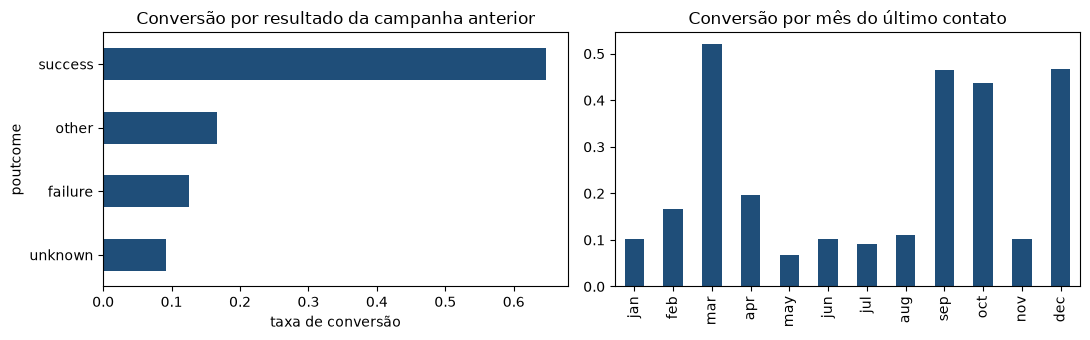

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
bruto.assign(y=bruto["y"].eq("yes")).groupby("poutcome")["y"].mean().sort_values().plot.barh(
    ax=eixos[0], color="#1f4e79", title="Conversão por resultado da campanha anterior")
ordem_meses = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
bruto.assign(y=bruto["y"].eq("yes")).groupby("month")["y"].mean().reindex(ordem_meses).plot.bar(
    ax=eixos[1], color="#1f4e79", title="Conversão por mês do último contato")
eixos[0].set_xlabel("taxa de conversão")
eixos[1].set_xlabel("")
plt.tight_layout()

- Quem **já contratou numa campanha anterior** (`poutcome = success`) converte ~65%, contra ~9% de quem nunca foi contatado (`unknown`). É o sinal mais forte da base.
- Meses com poucas ligações (mar, set, out, dez) têm conversão bem maior que maio, o mês com mais ligações. Isso tem mais a ver com **como a campanha foi conduzida** do que com o cliente (ver limitações).

### Distribuição e correlação das variáveis numéricas

Antes de modelar, vale entender como são as variáveis numéricas: como se distribuem e quanto cada uma se relaciona com o resultado.

In [6]:
numericas = m.COLUNAS_NUMERICAS
resumo = bruto[numericas].describe().T[["mean", "50%", "max"]]
resumo["assimetria"] = bruto[numericas].skew()
resumo.columns = ["média", "mediana", "máximo", "assimetria"]
resumo.round(1)

,média,mediana,máximo,assimetria
age,40.9,39.0,95.0,0.7
balance,1362.3,448.0,102127.0,8.4
day,15.8,16.0,31.0,0.1
campaign,2.8,2.0,63.0,4.9
pdays,40.2,-1.0,871.0,2.6
previous,0.6,0.0,275.0,41.8


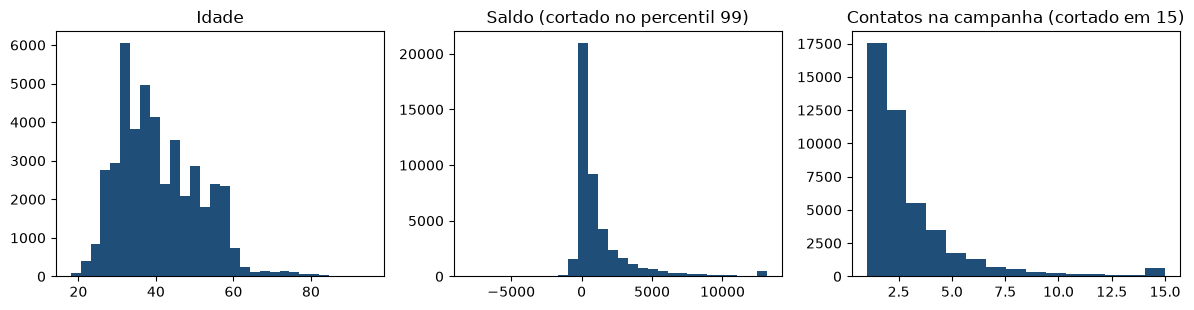

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.2))
bruto["age"].plot.hist(bins=30, ax=eixos[0], color="#1f4e79", title="Idade")
bruto["balance"].clip(upper=bruto["balance"].quantile(0.99)).plot.hist(
    bins=30, ax=eixos[1], color="#1f4e79", title="Saldo (cortado no percentil 99)")
bruto["campaign"].clip(upper=15).plot.hist(
    bins=15, ax=eixos[2], color="#1f4e79", title="Contatos na campanha (cortado em 15)")
for eixo in eixos:
    eixo.set_ylabel("")
plt.tight_layout()

- **Idade** é a única variável com distribuição razoavelmente simétrica (média 41, mediana 39).
- **Saldo, contatos na campanha e `previous`** são muito assimétricos para a direita: a média fica bem acima da mediana porque poucos clientes têm valores enormes (saldo de até R$ 102 mil e até 275 contatos anteriores). Por isso os gráficos cortam os extremos, e por isso a **padronização** do pré-processamento é importante para a regressão logística.
- **`pdays`** vale -1 para quem nunca foi contatado antes (a maioria dos clientes): é um código especial, não um número de dias de verdade.

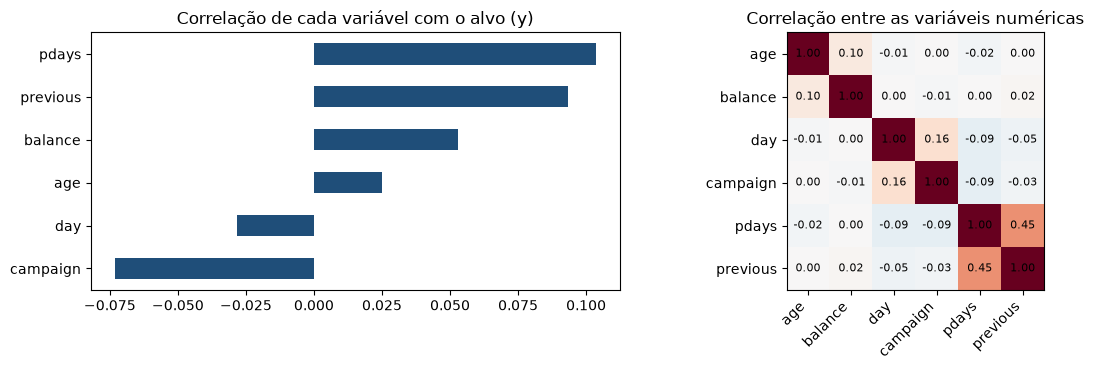

In [8]:
corr = bruto.assign(y=bruto["y"].eq("yes").astype(int))[numericas + ["y"]].corr()

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
corr["y"].drop("y").sort_values().plot.barh(ax=eixos[0], color="#1f4e79", title="Correlação de cada variável com o alvo (y)")
entre_variaveis = corr.drop(index="y", columns="y")
imagem = eixos[1].imshow(entre_variaveis, cmap="RdBu_r", vmin=-1, vmax=1)
eixos[1].set_xticks(range(len(numericas)), numericas, rotation=45, ha="right")
eixos[1].set_yticks(range(len(numericas)), numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        eixos[1].text(j, i, f"{entre_variaveis.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
eixos[1].set_title("Correlação entre as variáveis numéricas")
plt.tight_layout()

- **Todas as variáveis numéricas têm correlação fraca com o alvo** (no máximo 0,10, em `pdays`). Nenhuma, sozinha, explica quem contrata: o sinal está nas variáveis **categóricas**, principalmente `poutcome` (resultado da campanha anterior), que vimos acima.
- **`pdays` e `previous` têm correlação de 0,45** entre si: as duas descrevem o histórico de contatos anteriores e carregam informação parecida. Isso não prejudica a Random Forest, mas dificultaria interpretar os coeficientes da Regressão Logística.
- Correlação mede só relação **linear**; modelos como a Random Forest podem capturar relações que ela não mostra.

## 2. Por que remover `duration` (vazamento de dados)

`duration` é a duração da última ligação, em segundos. Ela só é conhecida **depois** que a ligação termina, e uma ligação curta quase sempre significa "não". Veja o poder preditivo dela **sozinha**:

In [9]:
auc_duration = roc_auc_score(bruto["y"].eq("yes"), bruto["duration"])
print(f"ROC AUC usando só a duração da ligação: {auc_duration:.3f}")

ROC AUC usando só a duração da ligação: 0.808


Uma única coluna com AUC acima de 0,8 parece ótima, mas **não pode ser usada** para decidir *quem ligar*, porque a ligação ainda não aconteceu. Um modelo com ela teria números bonitos no teste e seria inútil na prática. Por isso `carregar_dados()` descarta `duration` (a própria documentação da base recomenda isso).

In [10]:
df = carregar_dados()     # alvo em 0/1 e sem a coluna duration
print(df.shape)
df.head(3)

(45211, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0


## 3. Separar treino e teste

- **80% treino / 20% teste**. O teste fica guardado e só é usado para medir o resultado final.
- `stratify=y` garante a mesma proporção de "sim" nos dois conjuntos.
- `random_state=42` deixa o resultado reprodutível.
- O pré-processamento (padronização + one-hot) fica **dentro** de um `Pipeline`, então ele é ajustado só com o treino, sem "espiar" o teste.

In [11]:
X_treino, X_teste, y_treino, y_teste = m.separar_treino_teste(df)
print(f"treino: {len(X_treino)} linhas | {y_treino.mean():.2%} positivos")
print(f"teste:  {len(X_teste)} linhas | {y_teste.mean():.2%} positivos")

treino: 36168 linhas | 11.70% positivos
teste:  9043 linhas | 11.70% positivos


## 4. Baseline

O baseline é um `DummyClassifier(strategy="most_frequent")`: ele ignora as variáveis e responde sempre a classe mais comum ("não"). Qualquer modelo de verdade precisa **superar** esse ponto de referência, senão não está aprendendo nada útil.

## 5. Treinar e comparar modelos

| Modelo | Por que está aqui |
|---|---|
| Baseline | ponto de referência |
| Regressão Logística | modelo linear simples e interpretável |
| Árvore (sem limite) | incluída de propósito para mostrar overfitting |
| Random Forest | várias árvores com folhas mínimas de 20 exemplos, menos sujeita a overfitting |

**Métricas:**
- **acurácia**: % de acertos (engana em base desbalanceada);
- **acurácia balanceada**: média do acerto em cada classe (0,5 = chute);
- **precisão**: dos clientes que o modelo indicou, quantos contrataram;
- **recall**: dos que contrataram, quantos o modelo encontrou;
- **F1**: equilíbrio entre precisão e recall;
- **ROC AUC**: chance de o modelo dar nota maior a um "sim" do que a um "não" (0,5 = chute, 1 = perfeito). Não depende do limiar de 0,5, por isso é a métrica principal aqui.

In [12]:
modelos = m.criar_modelos()
resultados = m.treinar_e_avaliar(modelos, X_treino, X_teste, y_treino, y_teste)
resultados.round(3)

,modelo,conjunto,acuracia,acuracia_balanceada,precisao,recall,f1,roc_auc
0,Baseline (sempre 'não'),treino,0.883,0.500,0.000,0.000,0.000,0.500
1,Baseline (sempre 'não'),teste,0.883,0.500,0.000,0.000,0.000,0.500
2,Regressão Logística,treino,0.757,0.701,0.269,0.628,0.377,0.768
3,Regressão Logística,teste,0.755,0.698,0.266,0.624,0.373,0.772
4,Árvore (sem limite),treino,1.000,1.000,1.000,1.000,1.000,1.000
5,Árvore (sem limite),teste,0.831,0.613,0.298,0.329,0.313,0.613
6,Random Forest,treino,0.833,0.776,0.384,0.701,0.496,0.866
7,Random Forest,teste,0.815,0.737,0.343,0.634,0.445,0.800


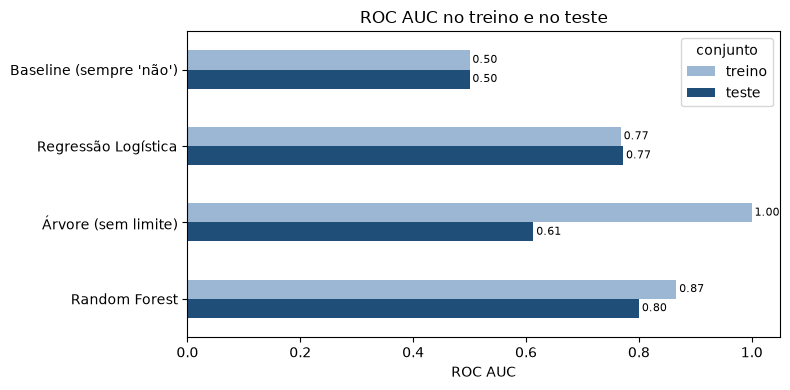

In [13]:
graficos.grafico_comparacao(resultados, "roc_auc");

**Leitura da tabela (conjunto de teste):**
- O **baseline tem a maior acurácia (88,3%)** e, mesmo assim, recall 0: não encontra nenhum cliente que contrataria. É o exemplo clássico de por que acurácia não serve sozinha.
- A **Random Forest** tem a melhor AUC (0,80) e o melhor F1 (0,45). A acurácia dela é *menor* que a do baseline porque ela passa a apostar em "sim", e erra parte dessas apostas, mas encontra 63% dos clientes que contratam.
- A **Regressão Logística** fica perto (AUC 0,77) com um modelo bem mais simples de explicar.

## 6. Validação cruzada

Um único split treino/teste pode ter tido sorte. A validação cruzada (5 folds, só com o treino) treina e avalia 5 vezes em partes diferentes:

In [14]:
cv = m.validacao_cruzada({k: v for k, v in modelos.items() if "sem limite" not in k}, X_treino, y_treino)
cv.round(3)

,modelo,auc_media,auc_desvio
0,Baseline (sempre 'não'),0.500,0.000
1,Regressão Logística,0.764,0.003
2,Random Forest,0.791,0.004


O desvio padrão é pequeno (≈0,004), então a ordem **Random Forest > Regressão Logística > Baseline** é estável e não depende da divisão escolhida. As AUCs da validação cruzada (0,79 e 0,76) também batem com as do teste (0,80 e 0,77).

## 7. Overfitting

**Overfitting** é quando o modelo decora o treino em vez de aprender padrões gerais. O sinal é uma diferença grande entre o desempenho no treino e no teste.

Comparando treino × teste (ROC AUC):

In [15]:
diferenca = resultados.pivot(index="modelo", columns="conjunto", values="roc_auc")[["treino", "teste"]]
diferenca["diferenca"] = diferenca["treino"] - diferenca["teste"]
diferenca.round(3).sort_values("diferenca", ascending=False)

conjunto,treino,teste,diferenca
modelo,,,
Árvore (sem limite),1.000,0.613,0.387
Random Forest,0.866,0.800,0.066
Baseline (sempre 'não'),0.500,0.500,0.000
Regressão Logística,0.768,0.772,-0.004


- **Árvore sem limite**: AUC **1,00 no treino** e **0,61 no teste**. Ela criou uma folha para quase cada cliente e decorou a base. É overfitting extremo.
- **Random Forest**: diferença de ~0,07. Há algum overfitting, mas controlado (folhas de no mínimo 20 exemplos e média de 300 árvores).
- **Regressão Logística**: diferença praticamente zero. O modelo é simples demais para decorar; aqui o limite é o oposto (pouca flexibilidade).

A curva abaixo mostra o mesmo fenômeno variando só a profundidade da árvore:

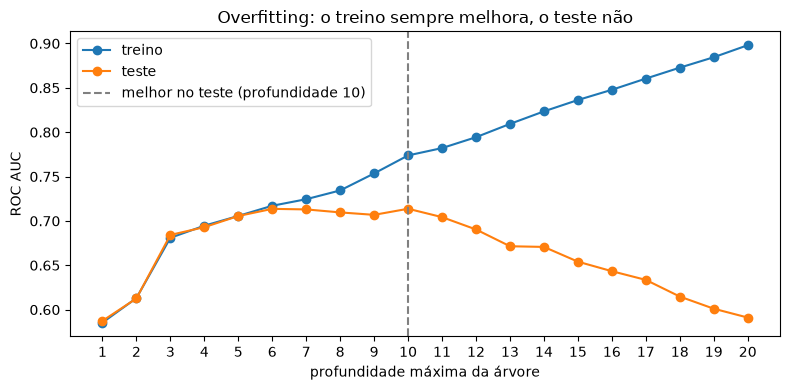

In [16]:
curva = m.curva_profundidade(X_treino, X_teste, y_treino, y_teste)
graficos.grafico_curva_profundidade(curva);

In [17]:
curva.loc[[0, 4, 5, 9, 14, 19]].round(3)

,profundidade,auc_treino,auc_teste
0,1,0.585,0.587
4,5,0.706,0.706
5,6,0.717,0.714
9,10,0.774,0.714
14,15,0.836,0.654
19,20,0.898,0.591


Até profundidade ~6 treino e teste sobem juntos (o modelo está aprendendo). Depois disso, o treino continua subindo e o teste **cai**: cada nível extra de profundidade só serve para decorar.

> Observação honesta: esta curva usa o conjunto de teste só para **ilustrar** o conceito. Para escolher hiperparâmetros de verdade, o certo é usar validação cruzada no treino (como na seção 6), deixando o teste intocado.

## 8. O que o modelo significa na prática

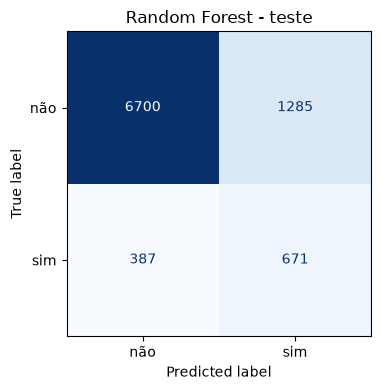

In [18]:
floresta = modelos["Random Forest"]
graficos.grafico_matriz_confusao(floresta, X_teste, y_teste, "Random Forest - teste");

### Onde o modelo erra

A matriz de confusão mostra o total de erros, mas não **em quem** eles acontecem. Abaixo, por grupo de clientes: quantos clientes há, qual a conversão real, em quantos o modelo apostou "sim" e o **recall** (dos que de fato contrataram, quantos o modelo encontrou).

In [19]:
previsto = floresta.predict(X_teste)
teste = X_teste.assign(real=y_teste.values, previsto=previsto)


def erros_por(coluna, faixas=None):
    grupo = pd.cut(teste[coluna], faixas) if faixas else teste[coluna]
    tabela = teste.groupby(grupo, observed=True).agg(
        clientes=("real", "size"), conversao_real=("real", "mean"), previsto_sim=("previsto", "mean"))
    positivos = teste["real"] == 1
    tabela["recall"] = teste[positivos].groupby(grupo[positivos], observed=True)["previsto"].mean()
    return tabela.round(2)


print("Por resultado da campanha anterior (poutcome)")
display(erros_por("poutcome"))
print("Por tipo de contato (contact)")
display(erros_por("contact"))
print("Por faixa etária")
display(erros_por("age", [17, 30, 40, 50, 60, 100]))

Por resultado da campanha anterior (poutcome)


,clientes,conversao_real,previsto_sim,recall
poutcome,,,,
failure,1012,0.14,0.34,0.68
other,355,0.17,0.40,0.74
success,306,0.65,1.00,1.00
unknown,7370,0.09,0.16,0.50


Por tipo de contato (contact)


,clientes,conversao_real,previsto_sim,recall
contact,,,,
cellular,5820,0.15,0.30,0.69
telephone,589,0.11,0.33,0.84
unknown,2634,0.04,0.00,0.04


Por faixa etária


,clientes,conversao_real,previsto_sim,recall
age,,,,
"(17, 30]",1327,0.16,0.36,0.73
"(30, 40]",3552,0.10,0.18,0.58
"(40, 50]",2256,0.09,0.14,0.49
"(50, 60]",1689,0.11,0.18,0.61
"(60, 100]",219,0.43,0.99,1.00


- **Cliente que já contratou antes (`success`)**: o modelo aposta "sim" em todos, e acerta: recall 1,00 e conversão real de 65%. É onde ele é mais confiável.
- **Cliente nunca contatado (`unknown`)**, o grupo maior: o modelo só encontra **metade** dos que contratariam (recall 0,50). Falta informação sobre esses clientes, e é aqui que se perdem mais vendas.
- **Contato `unknown`**: o modelo praticamente nunca aposta "sim" (recall 0,04). A conversão real nesse grupo é só 4%, então é uma decisão razoável, mas significa que esses poucos clientes que contratariam são sempre perdidos.
- **Clientes com mais de 60 anos** (apenas 219 no teste): o modelo aposta "sim" em quase todos, mas só 43% contratam. Com tão pouca amostra, ele provavelmente aprendeu um padrão que vale para poucos casos; é um sinal de **overfitting local** e de que a previsão para esse grupo é pouco confiável.
- No geral, só cerca de **1 em cada 3** clientes indicados pelo modelo contrata (precisão de 0,34): o modelo ajuda a priorizar, mas ainda gera muitas ligações perdidas.

In [20]:
# Se o banco ligar só para os 20% de clientes com maior probabilidade prevista:
probabilidades = floresta.predict_proba(X_teste)[:, 1]
ranking = pd.DataFrame({"prob": probabilidades, "y": y_teste.values}).sort_values("prob", ascending=False)
top20 = ranking.head(int(len(ranking) * 0.20))

taxa_aleatoria = y_teste.mean()
print(f"Conversão ligando para clientes aleatórios: {taxa_aleatoria:.1%}")
print(f"Conversão ligando para o top 20% do modelo: {top20['y'].mean():.1%} "
      f"({top20['y'].mean() / taxa_aleatoria:.1f}x melhor)")
print(f"Esse top 20% contém {top20['y'].sum() / y_teste.sum():.0%} de todos os clientes que contratariam")

Conversão ligando para clientes aleatórios: 11.7%
Conversão ligando para o top 20% do modelo: 35.8% (3.1x melhor)


Esse top 20% contém 61% de todos os clientes que contratariam


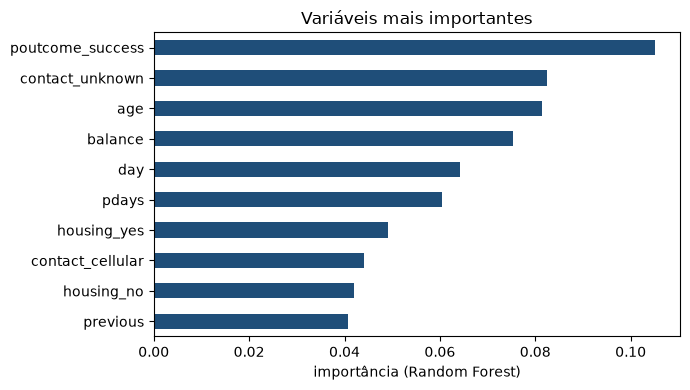

In [21]:
graficos.grafico_importancia(m.importancia_variaveis(floresta));

As variáveis mais importantes fazem sentido de negócio: **sucesso em campanha anterior** (`poutcome_success`), **tipo de contato** (`contact_unknown`), **idade**, **saldo** e **tempo desde o último contato** (`pdays`). A importância da Random Forest mede quanto cada variável ajuda a separar as classes, **não** se ela aumenta ou diminui a chance (para isso, os coeficientes da Regressão Logística ajudam mais).

## 9. Conclusões e limitações

**Conclusões**
1. O baseline tem 88% de acurácia e zero utilidade: em bases desbalanceadas, **ROC AUC, recall e F1** contam a história real.
2. A **Random Forest** foi o melhor modelo (AUC 0,80 no teste, 0,79 na validação cruzada), contra 0,50 do baseline. Ligando só para os 20% de clientes mais bem ranqueados, a conversão fica bem acima da de uma lista aleatória (números na seção 8).
3. A **árvore sem limite** mostrou overfitting na prática: perfeita no treino, fraca no teste. Limitar a complexidade (profundidade, tamanho mínimo das folhas, média de várias árvores) resolve boa parte disso.
4. Remover `duration` deixa as métricas mais baixas, mas **honestas**: o modelo usa só informação disponível antes da ligação.

**Limitações**
- **Dados antigos e de outro país** (Portugal, 2008–2010, período da crise financeira). O comportamento de clientes brasileiros hoje pode ser outro.
- **Variáveis de campanha** como `month`, `day` e `contact` descrevem *como o banco ligou*, não só o cliente. O modelo pode estar aprendendo a estratégia da campanha antiga, que não se repete igual.
- **Limiar fixo em 0,5**: na prática, o ponto de corte deveria vir do custo de uma ligação × lucro de uma venda.
- **Sem ajuste fino de hiperparâmetros**: os valores foram escolhidos de forma simples para manter o projeto explicável. Um `GridSearchCV` poderia melhorar um pouco.
- **Probabilidades não calibradas**: a Random Forest com `class_weight="balanced"` ordena bem os clientes, mas a "probabilidade" que ela dá não deve ser lida como chance real sem calibração.